# Baselines

In diesem Notebook werden alle drei CNN-Modell plus das ViT über mehrere Epochen lang trainiert um eine grundsätzliche Baseline zu generieren für meine Späteren Experimente mit Vision Transformer

In [1]:
import sys
sys.path.insert(0, "..") # Projektroot in Path
import os
os.chdir("..")

import yaml
from src.utils.seed import set_seed, get_device
from src.utils.data import make_food11_loaders
from src.utils.training import run_training, evaluate
from src.utils.metrics import count_params, count_trainable_params
from src.models.cnn_baseline import build_cnn_baseline
from src.models.vit import build_vit_from_cfg

import pandas as pd
import matplotlib.pyplot as plt


/Users/matsadel/Desktop/Master Informatik/MasterThesis/masterenv/lib/python3.12/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


In [2]:
with open("configs/default.yaml") as f:
    cfg = yaml.safe_load(f)
    
set_seed(cfg["seed"])
device=get_device()
print("Device: ", device)

Device:  mps


In [3]:
train_loader, val_loader, test_loader, num_classes = make_food11_loaders(
    **cfg["dataset"]
    )

print(f"Classes: {num_classes} | Train: {len(train_loader.dataset)} | Val: {len(val_loader.dataset)}")

Classes: 11 | Train: 9866 | Val: 3430


In [8]:
MODELS = {
    "vit_model": (lambda: build_vit_from_cfg(num_classes, cfg["model"]), 3e-4),
    "resnet18": (lambda: build_cnn_baseline('resnet18.a1_in1k', num_classes), 1e-4),
    "efficientnet_b0": (lambda:build_cnn_baseline('efficientnet_b0.ra_in1k', num_classes), 1e-4),
    "mobilenetv3_large": (lambda: build_cnn_baseline('mobilenetv3_large_100.ra_in1k', num_classes), 1e-4),
}
# lambda to prevent the model to build instantly, it should only build when it is called upon in the training

In [9]:
results = []
histories = {} # for learning curve

for name, (build_fn, lr) in MODELS.items():
    print(f"\n === {name} ===")
    model = build_fn()
    
    best_val, history = run_training(
        model, train_loader, val_loader, device,
        epochs=30, lr=lr, weight_decay=1e-4, patience=5 
    )
    
    _, test_acc = evaluate(model, test_loader, device)
    histories[name] = history
    
    results.append({
        "model": name,
        "params_M": round(count_params(model) / 1e6, 2),
        "trainable_M": round(count_trainable_params(model) / 1e6, 2),
        "best_val_acc": round(best_val, 4),
        "test_acc": round(test_acc, 4),
    })


 === vit_model ===


Epoch 001/30 | train_acc=0.9047 | val_acc=0.9394
Epoch 002/30 | train_acc=0.9636 | val_acc=0.9411
Epoch 003/30 | train_acc=0.9734 | val_acc=0.9414
Epoch 004/30 | train_acc=0.9771 | val_acc=0.9399
Epoch 005/30 | train_acc=0.9807 | val_acc=0.9394
Epoch 006/30 | train_acc=0.9849 | val_acc=0.9277
Epoch 007/30 | train_acc=0.9855 | val_acc=0.9181
Epoch 008/30 | train_acc=0.9826 | val_acc=0.9379
Early stopping at epoch 8

 === resnet18 ===
Epoch 001/30 | train_acc=0.4192 | val_acc=0.6519
Epoch 002/30 | train_acc=0.7149 | val_acc=0.7860
Epoch 003/30 | train_acc=0.8054 | val_acc=0.8262
Epoch 004/30 | train_acc=0.8420 | val_acc=0.8434
Epoch 005/30 | train_acc=0.8706 | val_acc=0.8513
Epoch 006/30 | train_acc=0.8864 | val_acc=0.8612
Epoch 007/30 | train_acc=0.9028 | val_acc=0.8673
Epoch 008/30 | train_acc=0.9154 | val_acc=0.8706
Epoch 009/30 | train_acc=0.9221 | val_acc=0.8796
Epoch 010/30 | train_acc=0.9318 | val_acc=0.8834
Epoch 011/30 | train_acc=0.9381 | val_acc=0.8805
Epoch 012/30 | train_acc

In [10]:
df = pd.DataFrame(results)
print(df.to_string(index=False))

df.to_csv("results/baseline_food11.csv", index=False)
print("\nSaved to results/baselines_food11.csv")

            model  params_M  trainable_M  best_val_acc  test_acc
        vit_model     21.67         3.55        0.9414    0.9483
         resnet18     11.18        11.18        0.8936    0.9160
  efficientnet_b0      4.02         4.02        0.9122    0.9301
mobilenetv3_large      4.22         4.22        0.9070    0.9256

Saved to results/baselines_food11.csv


Test Acc > Val Acc bei allen Modellen ist ungewöhnlich. Food11s evaluation Split ist aber leicht anders als validation, wodurch diese Ergebnisse trotzdem plausibel sind. 

Efficient net ist mit nur 4M parametern auf 93 Prozent gekommen was sehr starke Ergebnisse sind. Resnet ist hier der klare verlierer.

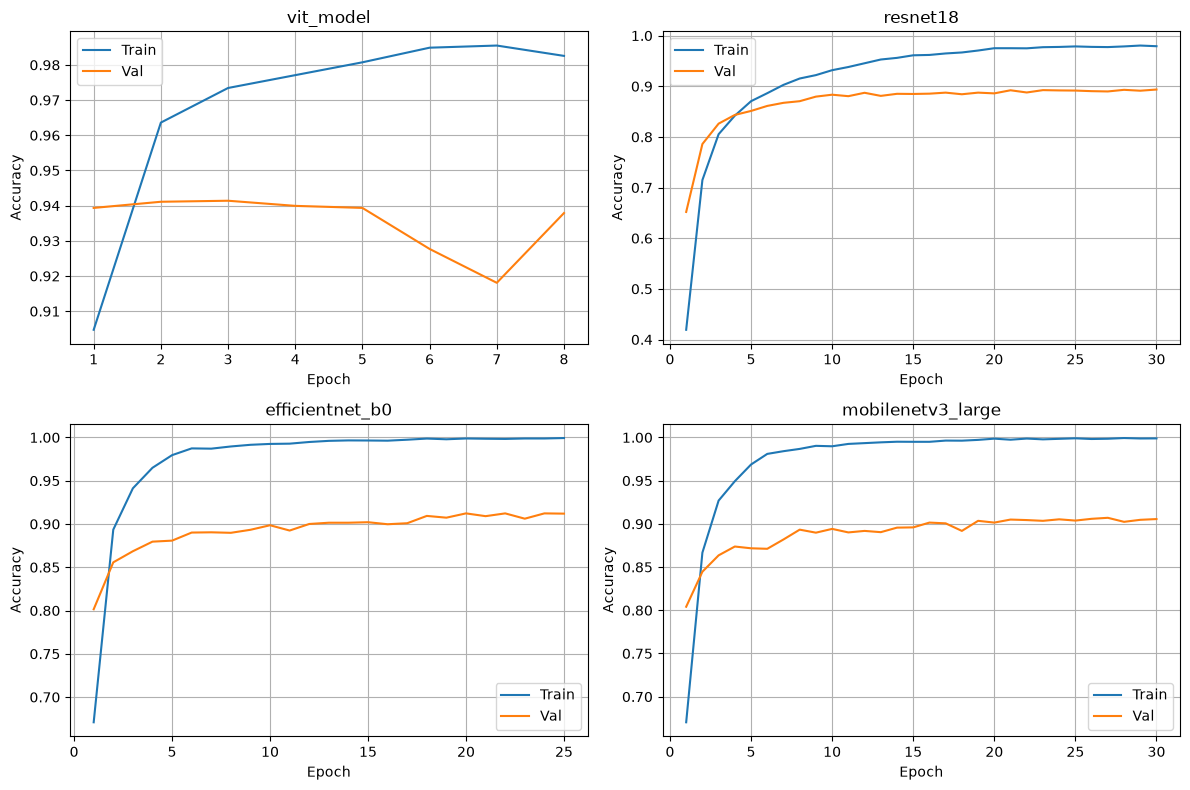

In [11]:
fig, axes = plt.subplots(2, 2, figsize=(12, 8))
axes = axes.flatten()

for ax, (name, history) in zip(axes, histories.items()):
    epochs = [h["epoch"] + 1 for h in history]
    ax.plot(epochs, [h["train_acc"] for h in history], label="Train")
    ax.plot(epochs, [h["val_acc"] for h in history], label="Val")
    ax.set_title(name)
    ax.set_xlabel("Epoch")
    ax.set_ylabel("Accuracy")
    ax.legend()
    ax.grid(True)
    
plt.tight_layout()
plt.savefig("results/baseline_learning_curves.png", dpi=150)
plt.show()
    